**Notebook 01:**
# Análisis Exploratorio de Datos del CIC-IDS2017

Este notebook realiza el análisis exploratorio de los archivos CSV del dataset CIC-IDS2017, tanto de forma individual como conjunta. Se identifican problemas de calidad de datos, se analiza la distribución de clases y se genera un dataset unificado para las fases de preprocesamiento y entrenamiento.

---

## 1. Requisitos

```bash
pip install pandas numpy matplotlib seaborn
```

Se requiere haber ejecutado previamente `00_descarga_dataset.ipynb` para contar con los archivos CSV en `data/raw/`.

In [3]:
import os
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
sns.set_style('whitegrid')

print(f"Fecha de ejecución: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Directorio de trabajo: {os.getcwd()}")

c:\Proyectos\TT-deteccionIntrusiones\tt_env\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.4)
  from scipy.stats import gaussian_kde


Fecha de ejecución: 2026-10-19 12:56:35
Directorio de trabajo: c:\Proyectos\TT-deteccionIntrusiones


In [4]:
# ============================================================
# Configuración de rutas
# ============================================================

PROJECT_ROOT = Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
GRAPHICS_DIR = PROJECT_ROOT / "graphics"

for dir_path in [PROCESSED_DIR, GRAPHICS_DIR]:
    dir_path.mkdir(parents=True, exist_ok=True)

EXPECTED_FILES = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
]

print(f"Directorio de datos crudos: {RAW_DIR}")
print(f"Directorio de datos procesados: {PROCESSED_DIR}")
print(f"Gráficos se guardarán en: {GRAPHICS_DIR}")
print(f"Archivos esperados: {len(EXPECTED_FILES)}")

Directorio de datos crudos: C:\Proyectos\TT-deteccionIntrusiones\data\raw
Directorio de datos procesados: C:\Proyectos\TT-deteccionIntrusiones\data\processed
Gráficos se guardarán en: C:\Proyectos\TT-deteccionIntrusiones\graphics
Archivos esperados: 8


## 2. Exploración individual por archivo

Se carga cada archivo CSV y se verifica:
- Número de filas y columnas
- Tipos de datos
- Presencia de la columna `Label`
- Valores nulos e infinitos
- Columnas con espacios en el nombre

In [5]:
# ============================================================
# Carga y exploración individual por archivo
# ============================================================

dataframes = {}
summary_individual = []

for fname in EXPECTED_FILES:
    path = RAW_DIR / fname

    if not path.exists():
        print(f"[ERROR] {fname}: archivo no encontrado")
        continue

    print(f"\n{'='*60}")
    print(f"Archivo: {fname}")
    print(f"{'='*60}")

    df = pd.read_csv(
        path,
        low_memory=False,
        encoding="utf-8",
        encoding_errors="replace"
    )
    df.columns = df.columns.str.strip()

    if "Label" in df.columns:
        df["Label"] = (
            df["Label"]
            .astype(str)
            .str.replace(r"[^\x00-\x7F]+", "-", regex=True)
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
        )

    n_rows, n_cols = df.shape
    print(f"Filas: {n_rows:,}")
    print(f"Columnas: {n_cols}")

    has_label = "Label" in df.columns
    print(f"Columna Label presente: {has_label}")

    label_counts = pd.Series(dtype=int)
    if has_label:
        label_counts = df["Label"].value_counts()
        print(f"Clases: {len(label_counts)}")
        for label, count in label_counts.items():
            print(f"  {label}: {count:,}")

    n_nulls = df.isnull().sum().sum()
    print(f"Valores nulos: {n_nulls:,}")

    numeric_cols_file = df.select_dtypes(include=np.number).columns
    n_infs = np.isinf(df[numeric_cols_file]).sum().sum()
    print(f"Valores infinitos: {n_infs:,}")

    n_numeric = len(numeric_cols_file)
    n_object = len(df.select_dtypes(include=["object", "string"]).columns)
    print(f"Columnas numéricas: {n_numeric}")
    print(f"Columnas categóricas: {n_object}")

    dataframes[fname] = df

    summary_individual.append({
        "archivo": fname,
        "filas": n_rows,
        "columnas": n_cols,
        "nulos": n_nulls,
        "infinitos": n_infs,
        "clases": len(label_counts) if has_label else 0,
    })

print(f"\n{'='*60}")
print("Archivos cargados:", len(dataframes))


Archivo: Monday-WorkingHours.pcap_ISCX.csv
Filas: 529,918
Columnas: 79
Columna Label presente: True
Clases: 1
  BENIGN: 529,918
Valores nulos: 64
Valores infinitos: 810
Columnas numéricas: 78
Columnas categóricas: 1

Archivo: Tuesday-WorkingHours.pcap_ISCX.csv
Filas: 445,909
Columnas: 79
Columna Label presente: True
Clases: 3
  BENIGN: 432,074
  FTP-Patator: 7,938
  SSH-Patator: 5,897
Valores nulos: 201
Valores infinitos: 327
Columnas numéricas: 78
Columnas categóricas: 1

Archivo: Wednesday-workingHours.pcap_ISCX.csv
Filas: 692,703
Columnas: 79
Columna Label presente: True
Clases: 6
  BENIGN: 440,031
  DoS Hulk: 231,073
  DoS GoldenEye: 10,293
  DoS slowloris: 5,796
  DoS Slowhttptest: 5,499
  Heartbleed: 11
Valores nulos: 1,008
Valores infinitos: 1,586
Columnas numéricas: 78
Columnas categóricas: 1

Archivo: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Filas: 170,366
Columnas: 79
Columna Label presente: True
Clases: 4
  BENIGN: 168,186
  Web Attack - Brute Force: 1,507
  W

In [ ]:
# ============================================================
# Resumen individual en tabla
# ============================================================

df_summary = pd.DataFrame(summary_individual)

print("\nResumen de exploración individual")
print("-" * 100)
display(df_summary)

total_rows = df_summary["filas"].sum()
total_nulls = df_summary["nulos"].sum()
total_infs = df_summary["infinitos"].sum()

print(f"\nTotal de registros: {total_rows:,}")
print(f"Total de valores nulos: {total_nulls:,}")
print(f"Total de valores infinitos: {total_infs:,}")


Resumen de exploración individual
----------------------------------------------------------------------------------------------------


,archivo,filas,columnas,nulos,infinitos,clases
0,Monday-WorkingHours.pcap_ISCX.csv,529918,79,64,810,1
1,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79,201,327,3
2,Wednesday-workingHours.pcap_ISCX.csv,692703,79,1008,1586,6
3,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,79,20,250,4
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,79,18,396,2
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79,28,216,2
6,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,79,15,727,2
7,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79,4,64,2



Total de registros: 2,830,743
Total de valores nulos: 1,358
Total de valores infinitos: 4,376


## 3. Unión de archivos en un solo dataset

Se concatenan todos los archivos en un único DataFrame para el análisis conjunto y las fases posteriores de preprocesamiento y entrenamiento.

In [7]:
# ============================================================
# Unión de archivos en un solo dataset
# ============================================================

print("Uniendo archivos en un solo DataFrame...")

df_full = pd.concat(dataframes.values(), ignore_index=True)
df_full.columns = df_full.columns.str.strip()

print("Dataset unificado:")
print(f"  Filas: {len(df_full):,}")
print(f"  Columnas: {len(df_full.columns)}")
print(f"  Uso de memoria: {df_full.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

Uniendo archivos en un solo DataFrame...
Dataset unificado:
  Filas: 2,830,743
  Columnas: 79
  Uso de memoria: 1833.79 MB


## 4. Análisis de distribución de clases

La distribución de clases es crítica para determinar si se requieren técnicas de balanceo antes del entrenamiento de los modelos.

In [ ]:
# ============================================================
# Distribución de clases
# ============================================================

label_counts = df_full["Label"].value_counts()
label_pct = df_full["Label"].value_counts(normalize=True) * 100

df_dist = pd.DataFrame({
    "Label": label_counts.index,
    "Count": label_counts.values,
    "Percentage": label_pct.values
}).reset_index(drop=True)

print("Distribución de clases en el dataset unificado")
print("=" * 60)
display(df_dist)

n_benign = label_counts.get("BENIGN", 0)
pct_benign = label_pct.get("BENIGN", 0)
n_attack = len(df_full) - n_benign
pct_attack = 100 - pct_benign

print(f"\nClase BENIGN: {n_benign:,} ({pct_benign:.2f}%)")
print(f"Registros de ataque: {n_attack:,} ({pct_attack:.2f}%)")
print(f"Clases de ataque: {len(label_counts) - 1}")

if n_benign > 0:
    max_attack = label_counts.drop("BENIGN", errors="ignore").max()
    ratio = n_benign / max_attack if max_attack > 0 else float("inf")
    print(f"Ratio BENIGN / ataque más frecuente: {ratio:.2f}")

Distribución de clases en el dataset unificado


,Label,Count,Percentage
0,BENIGN,2273097,80.300366
1,DoS Hulk,231073,8.162981
2,PortScan,158930,5.614427
3,DDoS,128027,4.522735
4,DoS GoldenEye,10293,0.363615
5,FTP-Patator,7938,0.280421
6,SSH-Patator,5897,0.208320
7,DoS slowloris,5796,0.204752
8,DoS Slowhttptest,5499,0.194260
9,Bot,1966,0.069452



Clase BENIGN: 2,273,097 (80.30%)
Registros de ataque: 557,646 (19.70%)
Clases de ataque: 14
Ratio BENIGN / ataque más frecuente: 9.84


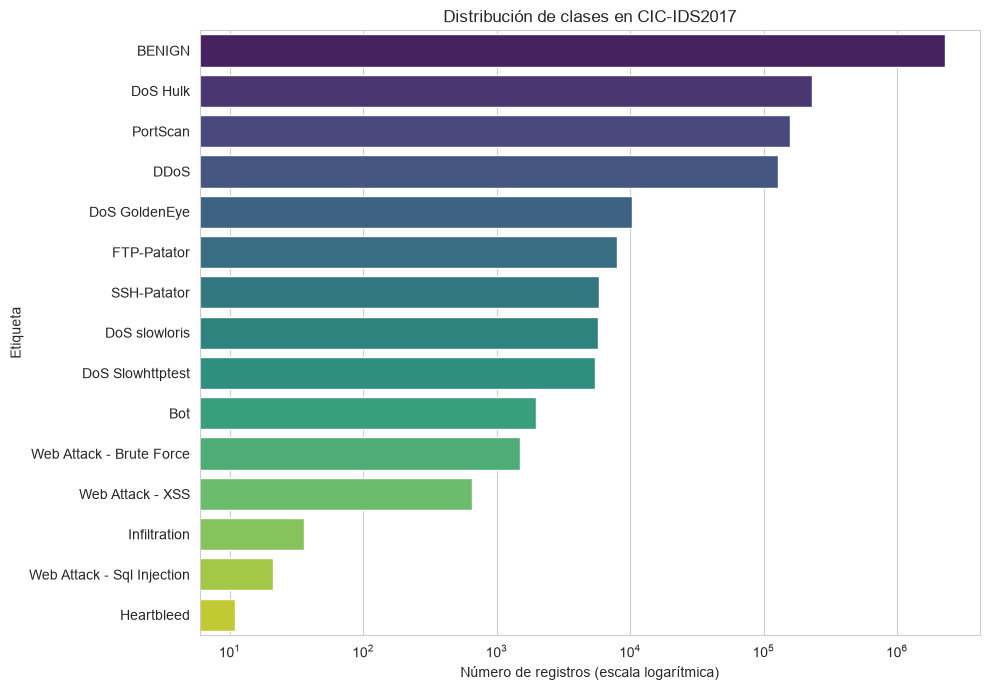

Gráfico guardado en: C:\Proyectos\TT-deteccionIntrusiones\graphics\distribucion_clases_log.png


In [9]:
# ============================================================
# Visualización de distribución de clases
# ============================================================

fig, ax = plt.subplots(figsize=(10, 7))

sns.barplot(
    data=df_dist,
    x="Count",
    y="Label",
    hue="Label",
    palette="viridis",
    legend=False,
    ax=ax
)

ax.set_xscale("log")
ax.set_title("Distribución de clases en CIC-IDS2017")
ax.set_xlabel("Número de registros (escala logarítmica)")
ax.set_ylabel("Etiqueta")

plt.tight_layout()
plt.savefig(GRAPHICS_DIR / "distribucion_clases_log.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Gráfico guardado en: {GRAPHICS_DIR / 'distribucion_clases_log.png'}")

## 5. Análisis de calidad de datos

Se identifican problemas comunes en el dataset CIC-IDS2017:
- Valores infinitos en características numéricas
- Valores nulos
- Tipos de datos inconsistentes
- Columnas con varianza cero

In [10]:
# ============================================================
# Análisis de calidad de datos
# ============================================================

print("Análisis de calidad de datos")
print("=" * 60)

numeric_cols = df_full.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df_full.select_dtypes(include=["object", "string"]).columns.tolist()

print(f"Columnas numéricas: {len(numeric_cols)}")
print(f"Columnas categóricas: {len(categorical_cols)}")

# Valores nulos
nulls_by_col = df_full.isnull().sum()
cols_with_nulls = nulls_by_col[nulls_by_col > 0].sort_values(ascending=False)

print(f"\nColumnas con valores nulos: {len(cols_with_nulls)}")
if len(cols_with_nulls) > 0:
    display(cols_with_nulls)

# Valores infinitos
infs_by_col = np.isinf(df_full[numeric_cols]).sum()
cols_with_infs = infs_by_col[infs_by_col > 0].sort_values(ascending=False)

print(f"\nColumnas con valores infinitos: {len(cols_with_infs)}")
if len(cols_with_infs) > 0:
    display(cols_with_infs)

# Copia para análisis sin modificar el original
df_analysis = df_full[numeric_cols].replace([np.inf, -np.inf], np.nan)

# Columnas con varianza cero o sin variación
std_by_col = df_analysis.std()
nunique_by_col = df_analysis.nunique(dropna=True)
zero_var_mask = (std_by_col == 0) | (nunique_by_col <= 1)
cols_zero_var = df_analysis.columns[zero_var_mask].tolist()

print(f"\nColumnas con varianza cero o sin variación: {len(cols_zero_var)}")
if len(cols_zero_var) > 0:
    print(cols_zero_var)
else:
    print("Ninguna")

# Valores negativos en características temporales o de tasa
temporal_keywords = ["Duration", "IAT", "Bytes/s", "Packets/s", "Rate"]
suspect_cols = [c for c in numeric_cols if any(k in c for k in temporal_keywords)]

neg_counts = (df_full[suspect_cols] < 0).sum()
neg_counts = neg_counts[neg_counts > 0].sort_values(ascending=False)

print(f"\nColumnas con valores negativos en features temporales/de tasa: {len(neg_counts)}")
if len(neg_counts) > 0:
    display(neg_counts)
else:
    print("Ninguna")

print(f"\nVerificación: df_full conserva {np.isinf(df_full[numeric_cols]).sum().sum():,} valores infinitos (sin modificar)")

Análisis de calidad de datos
Columnas numéricas: 78
Columnas categóricas: 1

Columnas con valores nulos: 1


Flow Bytes/s    1358
dtype: int64


Columnas con valores infinitos: 2


Flow Packets/s    2867
Flow Bytes/s      1509
dtype: int64


Columnas con varianza cero o sin variación: 8
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

Columnas con valores negativos en features temporales/de tasa: 7


Flow IAT Min      2891
Flow Packets/s     115
Flow Duration      115
Flow IAT Max       115
Flow IAT Mean      115
Flow Bytes/s        85
Fwd IAT Min         17
dtype: int64


Verificación: df_full conserva 4,376 valores infinitos (sin modificar)


In [ ]:
# ============================================================
# Estadísticas descriptivas de las características numéricas
# ============================================================

df_stats = df_full[numeric_cols].replace([np.inf, -np.inf], np.nan)

print("Estadísticas descriptivas (primeras 20 columnas numéricas)")
print("=" * 60)

desc = df_stats[numeric_cols[:20]].describe().T
display(desc)

print("\nEstadísticas por clase (muestra de 5 columnas)")
print("=" * 60)

sample_cols = numeric_cols[:5]
stats_by_label = df_full.groupby("Label")[sample_cols].mean()
display(stats_by_label)

Estadísticas descriptivas (primeras 20 columnas numéricas)


,count,mean,std,min,25%,50%,75%,max
Destination Port,2830743.0,8.071483e+03,1.828363e+04,0.0,53.000000,80.000000,4.430000e+02,6.553500e+04
Flow Duration,2830743.0,1.478566e+07,3.365374e+07,-13.0,155.000000,31316.000000,3.204828e+06,1.200000e+08
Total Fwd Packets,2830743.0,9.361160e+00,7.496728e+02,1.0,2.000000,2.000000,5.000000e+00,2.197590e+05
Total Backward Packets,2830743.0,1.039377e+01,9.973883e+02,0.0,1.000000,2.000000,4.000000e+00,2.919220e+05
Total Length of Fwd Packets,2830743.0,5.493024e+02,9.993589e+03,0.0,12.000000,62.000000,1.870000e+02,1.290000e+07
Total Length of Bwd Packets,2830743.0,1.616264e+04,2.263088e+06,0.0,0.000000,123.000000,4.820000e+02,6.554530e+08
Fwd Packet Length Max,2830743.0,2.075999e+02,7.171848e+02,0.0,6.000000,37.000000,8.100000e+01,2.482000e+04
Fwd Packet Length Min,2830743.0,1.871366e+01,6.033935e+01,0.0,0.000000,2.000000,3.600000e+01,2.325000e+03
Fwd Packet Length Mean,2830743.0,5.820194e+01,1.860912e+02,0.0,6.000000,34.000000,5.000000e+01,5.940857e+03
Fwd Packet Length Std,2830743.0,6.891013e+01,2.811871e+02,0.0,0.000000,0.000000,2.616295e+01,7.125597e+03



Estadísticas por clase (muestra de 5 columnas)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets
Label,,,,,
BENIGN,9419.545172,1.122082e+07,10.654173,12.138636,635.536886
Bot,17783.990844,3.509427e+05,3.193795,3.343845,2645.448627
DDoS,81.227382,1.695559e+07,4.472439,3.255821,31.908597
DoS GoldenEye,80.000000,2.312722e+07,5.904401,3.714078,418.430001
DoS Hulk,80.000000,5.708173e+07,5.279656,4.205688,281.331415
DoS Slowhttptest,80.000000,5.771989e+07,5.741771,0.963812,496.553555
DoS slowloris,80.000000,5.655437e+07,6.337129,1.655797,810.692029
FTP-Patator,21.007433,4.513245e+06,5.496977,7.808390,60.032124
Heartbleed,444.000000,1.106797e+08,2583.727273,1897.181818,12509.727273


## 6. Correlación entre características

Se analiza la correlación entre las características numéricas para identificar redundancias que puedan abordarse en la fase de selección de características.

In [ ]:
# ============================================================
# Matriz de correlación
# ============================================================

sample_size = min(50000, len(df_full))
df_sample = (
    df_full[numeric_cols]
    .sample(n=sample_size, random_state=42)
    .replace([np.inf, -np.inf], np.nan)
)

corr_matrix = df_sample.corr(method="pearson")

print(f"Matriz de correlación calculada sobre muestra de {sample_size:,} registros")
print(f"Dimensiones: {corr_matrix.shape}")

threshold_corr = 0.95
high_corr_pairs = []

cols = corr_matrix.columns
for i in range(len(cols)):
    for j in range(i):
        r = corr_matrix.iloc[i, j]
        if pd.notna(r) and abs(r) > threshold_corr:
            high_corr_pairs.append({
                "feature_1": cols[i],
                "feature_2": cols[j],
                "correlation": r,
                "abs_correlation": abs(r)
            })

df_high_corr = pd.DataFrame(high_corr_pairs)

if not df_high_corr.empty:
    df_high_corr = df_high_corr.sort_values("abs_correlation", ascending=False)

print(f"\nPares con correlación absoluta > {threshold_corr}: {len(df_high_corr)}")
if not df_high_corr.empty:
    display(df_high_corr.head(20))
else:
    print("Ninguno")

Matriz de correlación calculada sobre muestra de 50,000 registros
Dimensiones: (78, 78)

Pares con correlación absoluta > 0.95: 60


,feature_1,feature_2,correlation,abs_correlation
21,Avg Fwd Segment Size,Fwd Packet Length Mean,1.000000,1.000000
17,SYN Flag Count,Fwd PSH Flags,1.000000,1.000000
19,ECE Flag Count,RST Flag Count,1.000000,1.000000
18,CWE Flag Count,Fwd URG Flags,1.000000,1.000000
27,Fwd Header Length.1,Fwd Header Length,1.000000,1.000000
23,Avg Bwd Segment Size,Bwd Packet Length Mean,1.000000,1.000000
35,Subflow Fwd Bytes,Total Length of Fwd Packets,1.000000,1.000000
29,Subflow Fwd Packets,Total Fwd Packets,1.000000,1.000000
37,Subflow Bwd Packets,Total Backward Packets,1.000000,1.000000
45,Subflow Bwd Bytes,Total Length of Bwd Packets,1.000000,1.000000


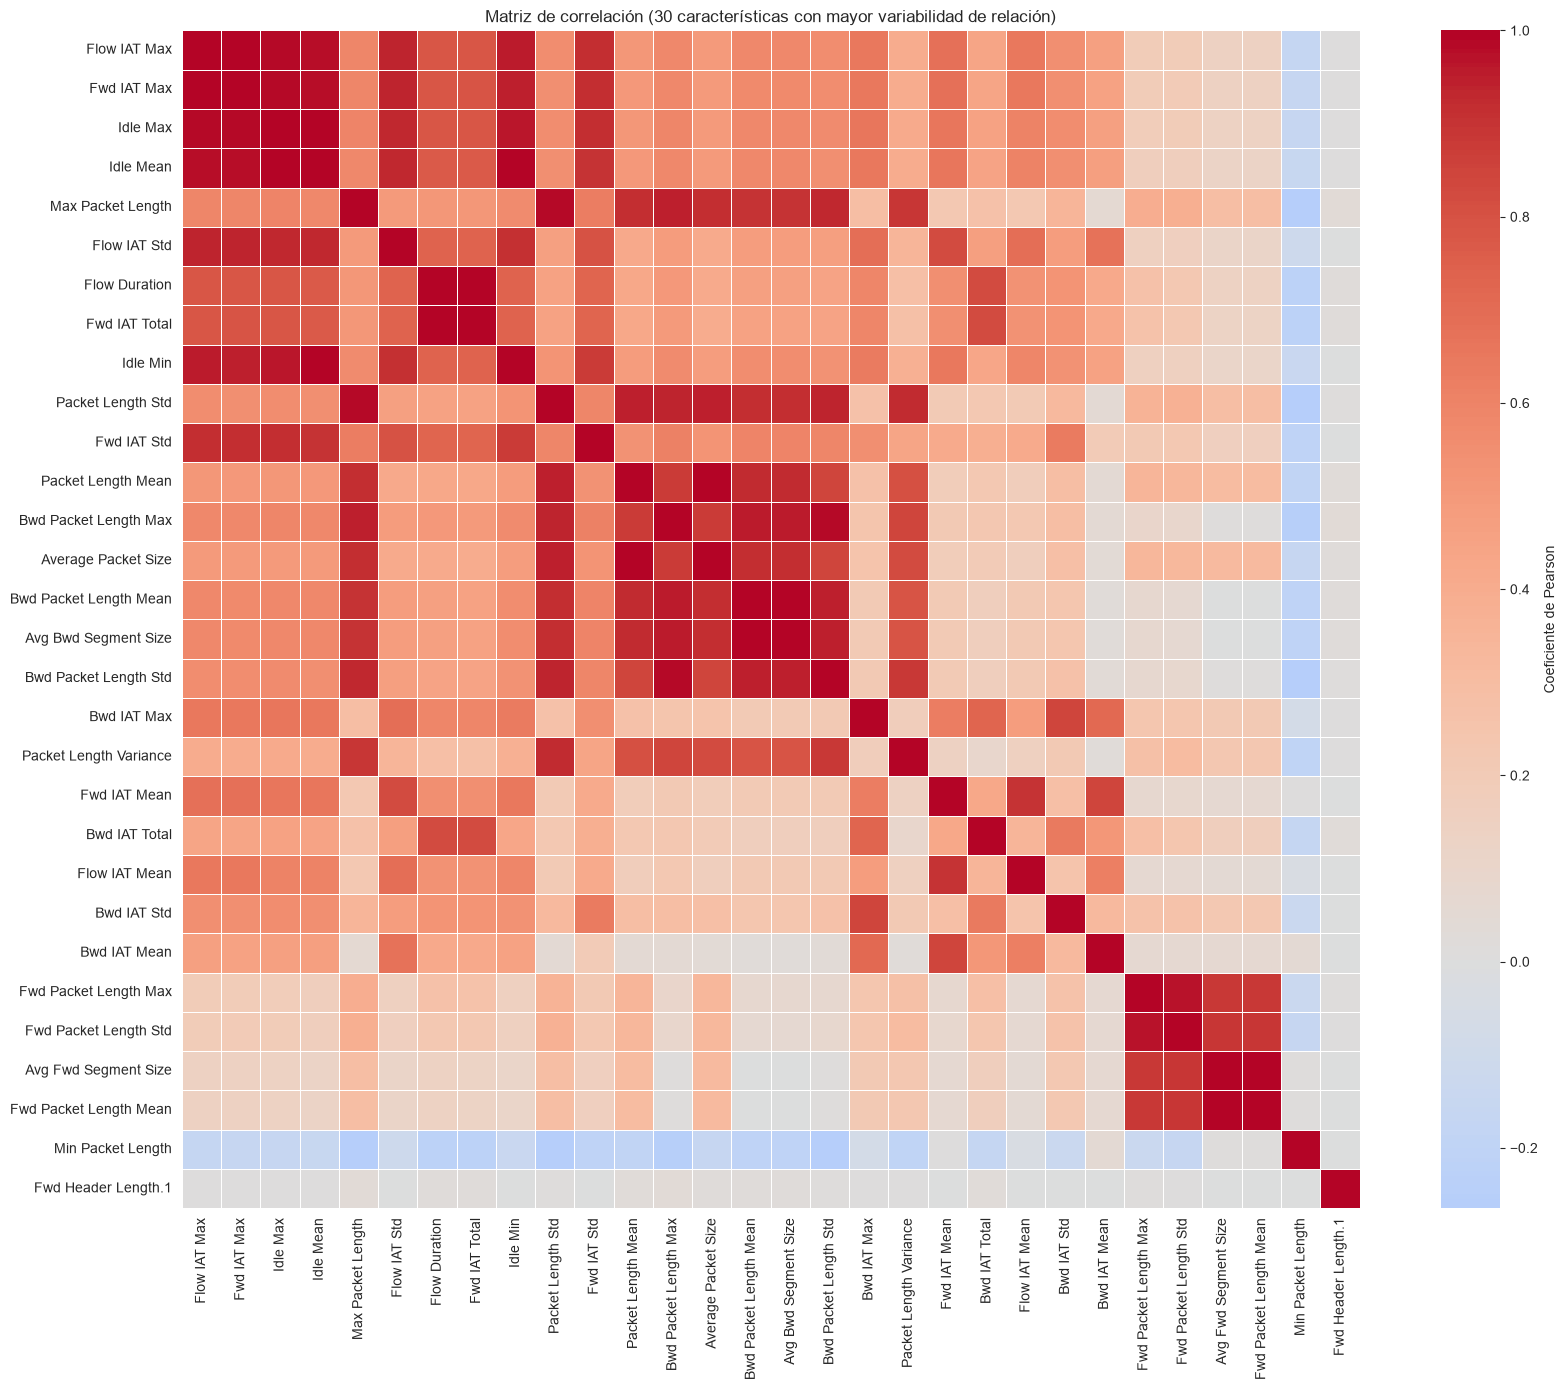

Gráfico guardado en: C:\Proyectos\TT-deteccionIntrusiones\graphics\correlacion_features.png


In [ ]:
# ============================================================
# Visualización de correlación (subconjunto informativo)
# ============================================================

mean_abs_corr = corr_matrix.abs().mean().sort_values(ascending=False)
features_plot = mean_abs_corr.index[:30].tolist()

corr_sub = corr_matrix.loc[features_plot, features_plot]

plt.figure(figsize=(18, 14))
sns.heatmap(
    corr_sub,
    annot=False,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Coeficiente de Pearson"}
)

plt.title("Matriz de correlación (30 características con mayor variabilidad de relación)")
plt.tight_layout()
plt.savefig(GRAPHICS_DIR / "correlacion_features.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Gráfico guardado en: {GRAPHICS_DIR / 'correlacion_features.png'}")

## 7. Guardado del dataset unificado

Se guarda el dataset unificado en formato CSV.gz para su uso en las fases de preprocesamiento y entrenamiento.

In [ ]:
# ============================================================
# Guardado del dataset unificado
# ============================================================

csvgz_path = PROCESSED_DIR / "CIC-IDS2017_unified.csv.gz"

try:
    df_full.to_csv(csvgz_path, index=False, compression="gzip")
    file_size = csvgz_path.stat().st_size / (1024 ** 2)
    print("\nDataset guardado en formato CSV.gz como alternativa.")
    print(f"Archivo: {csvgz_path}")
    print(f"Tamaño: {file_size:.2f} MB")

    print(f"Registros: {len(df_full):,}")
    print(f"Columnas: {len(df_full.columns)}")
except Exception as e:
    print(f"[ERROR] No se pudo guardar en CSV.gz: {e}")


Dataset guardado en formato CSV.gz como alternativa.
Archivo: C:\Proyectos\TT-deteccionIntrusiones\data\processed\CIC-IDS2017_unified.csv.gz
Tamaño: 227.01 MB
Registros: 2,830,743
Columnas: 79


## 8. Resumen del análisis exploratorio

In [ ]:
# ============================================================
# Resumen final del análisis exploratorio
# ============================================================

hallazgos = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Total de columnas",
        "Columnas numéricas",
        "Columnas categóricas",
        "Archivos CSV originales",
        "Clases totales",
        "Registros BENIGN",
        "Porcentaje BENIGN",
        "Registros de ataque",
        "Porcentaje de ataque",
        "Valores nulos totales",
        "Columnas con valores nulos",
        "Valores infinitos totales",
        "Columnas con valores infinitos",
        "Columnas con varianza cero",
        "Lista de columnas con varianza cero",
        "Pares con correlación absoluta > 0.95",
        "Columnas con negativos en features temporales/de tasa"
    ],
    "Valor": [
        f"{len(df_full):,}",
        f"{len(df_full.columns)}",
        f"{len(numeric_cols)}",
        f"{len(categorical_cols)}",
        f"{len(EXPECTED_FILES)}",
        f"{len(label_counts)}",
        f"{n_benign:,}",
        f"{pct_benign:.2f}%",
        f"{n_attack:,}",
        f"{pct_attack:.2f}%",
        f"{int(total_nulls):,}",
        ", ".join(cols_with_nulls.index.tolist()) if len(cols_with_nulls) > 0 else "Ninguna",
        f"{int(total_infs):,}",
        ", ".join(cols_with_infs.index.tolist()) if len(cols_with_infs) > 0 else "Ninguna",
        f"{len(cols_zero_var)}",
        ", ".join(cols_zero_var) if len(cols_zero_var) > 0 else "Ninguna",
        f"{len(df_high_corr)}",
        f"{len(neg_counts)}"
    ]
})

print("Resumen final del análisis exploratorio")
print("=" * 80)
display(hallazgos)

Resumen final del análisis exploratorio


,Indicador,Valor
0,Total de registros,"2,830,743"
1,Total de columnas,79
2,Columnas numéricas,78
3,Columnas categóricas,1
4,Archivos CSV originales,8
5,Clases totales,15
6,Registros BENIGN,"2,273,097"
7,Porcentaje BENIGN,80.30%
8,Registros de ataque,"557,646"
9,Porcentaje de ataque,19.70%



Tabla guardada en: C:\Proyectos\TT-deteccionIntrusiones\tables\01_hallazgos_eda.csv
